## 0. Setup Awal

In [2]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputLogisticRegressionElastic_NetAntiBurnout'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [3]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

Jumlah data awal: 50000


### 1.2 Identifikasi Kolom yang Digunakan

In [4]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [5]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,Poor,High,Weekly,Yes,Yes,No,Yes,No,Yes,Average
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,Poor,Moderate,Weekly,Yes,Yes,Yes,No,Yes,No,Good
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,Average,Moderate,Daily,Yes,No,No,No,Yes,No,Average
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,Good,Low,Weekly,Yes,No,No,No,No,Yes,Good
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,Excellent,Low,Never,Yes,No,No,No,Yes,No,Poor


### 2.2 Encoding Data Kategorikal

In [6]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,1,3,2,1,1,1,1,1,0,0.0,2
1,1,3,1,1,1,1,0,0,1,1.0,1
2,0,2,1,0,1,0,1,0,1,1.0,2
3,2,1,0,1,1,0,1,0,0,0.0,1
4,0,0,0,3,1,0,1,0,1,1.0,3


### 2.3 Penanganan Missing Values

In [7]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

print(
    '\nJumlah missing value:'
)
print(X.isnull().sum().sum())

Missing value sebelum preprocessing:
Age                               250
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Life_Satisfaction                 700
Productivity_Score                950
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

Standardisasi dilakukan di dalam Pipeline pada data latih dan setiap fold cross-validation.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape

((40000, 30), (10000, 30))

### 2.6 Data Bersih

In [9]:
print('Dimensi data fitur (X):', X.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X.isnull().sum().sum())
print("Kolom yang dikecualikan: Mental_Health_Status, Burnout_Score, Person_ID")
print('\nDistribusi kelas target (y):')
print(y.value_counts())

X.head()

Dimensi data fitur (X): (50000, 30)
Dimensi data latih (X_train): (40000, 30)
Dimensi data uji (X_test): (10000, 30)
Jumlah missing value: 12900
Kolom yang dikecualikan: Mental_Health_Status, Burnout_Score, Person_ID

Distribusi kelas target (y):
Burnout_Risk
0    25369
1    14780
2     9851
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,3,2,1,1,1,1,1,0,0.0,2
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,3,1,1,1,1,0,0,1,1.0,1
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,2,1,0,1,0,1,0,1,1.0,2
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,1,0,1,1,0,1,0,0,0.0,1
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,0,0,3,1,0,1,0,1,1.0,3


## 3. Modeling

### 3.1 Inisialisasi Model Logistic Regression Elastic Net

In [10]:
pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            penalty='elasticnet',
            solver='saga',
            max_iter=10000,
            tol=1e-4,
            random_state=42
        ))
    ]
)

param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__l1_ratio': [0.25, 0.5, 0.75]
}

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring={
        'accuracy': 'accuracy',
        'precision_macro': 'precision_macro',
        'recall_macro': 'recall_macro',
        'f1_macro': 'f1_macro',
        'f1_weighted': 'f1_weighted'
    },
    cv=cv,
    n_jobs=-1,
    refit='f1_macro',
    return_train_score=True
)

tracemalloc.start()
start_time = time.perf_counter()

search.fit(
    X_train,
    y_train
)

train_time = time.perf_counter() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)
model = search.best_estimator_

print('Parameter terbaik:', search.best_params_)
print(f'F1 Macro Cross-Validation Terbaik: {search.best_score_:.4f}')
print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Parameter terbaik: {'classifier__C': 0.01, 'classifier__l1_ratio': 0.75}
F1 Macro Cross-Validation Terbaik: 0.7959
Waktu Eksekusi Training: 214.2773 detik
Penggunaan Memori Peak: 40.6447 MB


### 3.3 Prediksi Data Uji

In [12]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
15522,2,2
35306,0,0
90,1,1
48756,0,0
19181,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [13]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.9018    0.8855    0.8936      5074
Moderate (1)     0.6772    0.7233    0.6995      2956
    High (2)     0.8232    0.7777    0.7998      1970

    accuracy                         0.8163     10000
   macro avg     0.8008    0.7955    0.7976     10000
weighted avg     0.8200    0.8163    0.8177     10000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[4493  581    0]
 [ 489 2138  329]
 [   0  438 1532]]


### 4.3 Metrik Evaluasi Data Uji

In [15]:
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.8163
Precision (Macro)  : 0.8008
Recall (Macro)     : 0.7955
F1-Score (Macro)   : 0.7976
F1-Score (Weighted): 0.8177


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [16]:
cv_results = search.cv_results_
best_index = search.best_index_

cv_metric_names = {
    'Accuracy': 'accuracy',
    'Precision (Macro)': 'precision_macro',
    'Recall (Macro)': 'recall_macro',
    'F1-Score (Macro)': 'f1_macro',
    'F1-Score (Weighted)': 'f1_weighted'
}

cv_rows = []
for fold in range(5):
    row = {'Fold': f'Fold {fold + 1}'}
    for metric_name, scorer_name in cv_metric_names.items():
        key = f'split{fold}_test_{scorer_name}'
        if key in cv_results:
            row[metric_name] = cv_results[key][best_index]
    cv_rows.append(row)

df_cv = pd.DataFrame(cv_rows)
df_cv.loc['Mean'] = ['Mean'] + [df_cv[col].mean() for col in df_cv.columns[1:]]
df_cv.loc['Std'] = ['Std'] + [df_cv[col].std() for col in df_cv.columns[1:]]
df_cv

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.814250,0.802007,0.789696,0.794598,0.815845
1,Fold 2,0.819750,0.806699,0.795156,0.800234,0.820371
2,Fold 3,0.816500,0.807067,0.793703,0.799301,0.817747
3,Fold 4,0.810125,0.798075,0.785645,0.790580,0.811826
4,Fold 5,0.812875,0.802931,0.788578,0.794809,0.813617
Mean,Mean,0.814700,0.803356,0.790556,0.795904,0.815881
Std,Std,0.003262,0.003312,0.003459,0.003508,0.003007


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [17]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Logistic Regression Elastic Net',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,Logistic Regression Elastic Net,214.2773,40.6447


### 4.6 Ringkasan Evaluasi Model

In [18]:
best_params = search.best_params_

penalty_label = 'elasticnet'
l1_ratio_value = 0.5
C_value = best_params['classifier__C']

if 'classifier__l1_ratio' in best_params:
    l1_ratio_value = best_params['classifier__l1_ratio']

evaluation_result = pd.DataFrame(
    {
        'Model': ['Logistic Regression Elastic Net'],
        'Feature_Count': [X.shape[1]],
        'Excluded_Feature': ['Mental_Health_Status'],
        'Penalty': [penalty_label],
        'L1_Ratio': [l1_ratio_value],
        'C': [C_value],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(search.cv_results_['mean_test_accuracy'][search.best_index_], 4)],
        'CV_5Fold_F1_Macro_Mean': [round(search.best_score_, 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Feature_Count,Excluded_Feature,Penalty,L1_Ratio,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Logistic Regression Elastic Net,30,Mental_Health_Status,elasticnet,0.75,0.01,0.8163,0.8008,0.7955,0.7976,0.8177,0.8147,0.7959,214.2773,40.6447


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

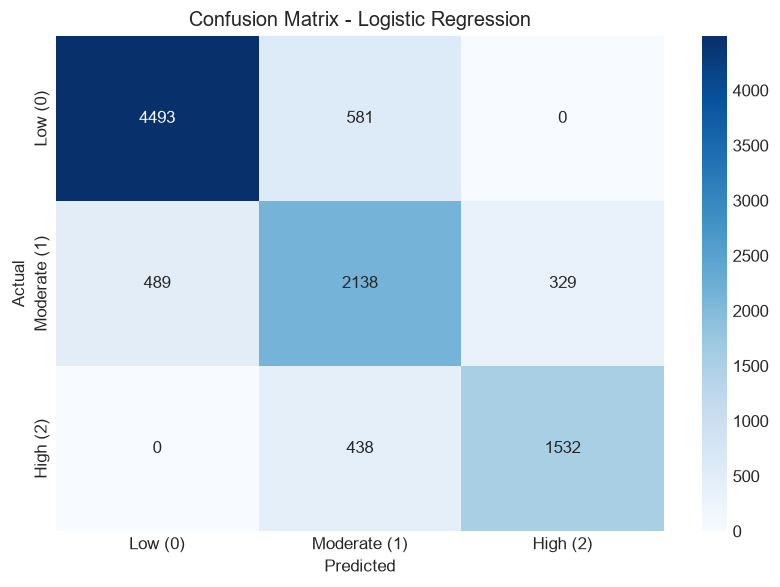

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_logistic_regression.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

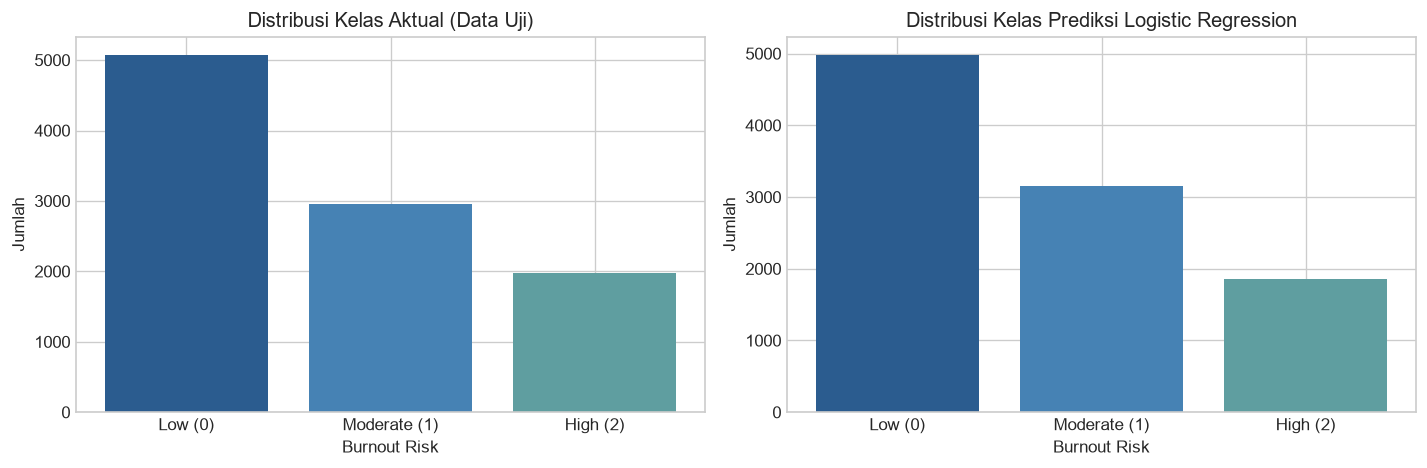

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

actual_counts = y_test.value_counts().reindex([0, 1, 2], fill_value=0)
predicted_counts = pd.Series(y_pred).value_counts().reindex([0, 1, 2], fill_value=0)

axes[0].bar(target_names, actual_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

axes[1].bar(target_names, predicted_counts.values, color=['#2b5c8f', '#4682b4', '#5f9ea0'])
axes[1].set_title('Distribusi Kelas Prediksi Logistic Regression')
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_logistic_regression.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

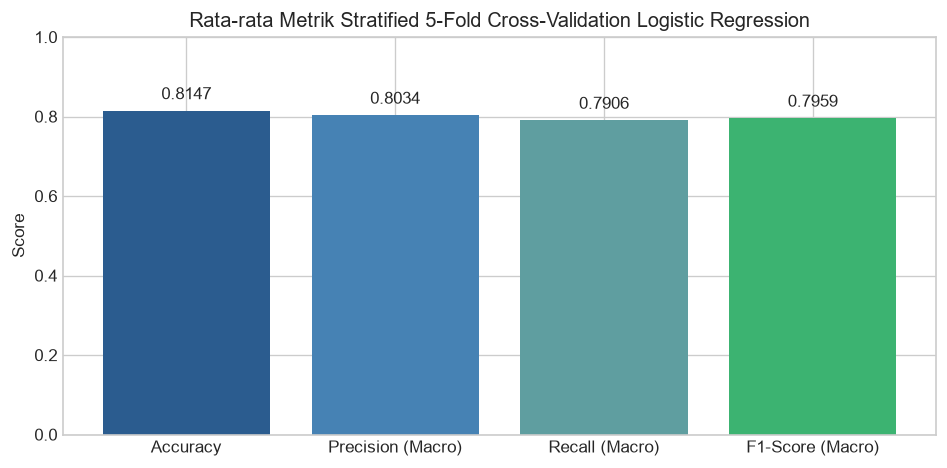

In [21]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    search.cv_results_['mean_test_accuracy'][search.best_index_],
    search.cv_results_['mean_test_precision_macro'][search.best_index_],
    search.cv_results_['mean_test_recall_macro'][search.best_index_],
    search.cv_results_['mean_test_f1_macro'][search.best_index_]
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation Logistic Regression')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_logistic_regression.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Koefisien Fitur Model Logistic Regression

In [22]:
classifier = model.named_steps['classifier']

feature_names = X.columns.tolist()
class_names = [f'Class_{name}' for name in target_names]

df_coef = pd.DataFrame(
    classifier.coef_,
    columns=feature_names,
    index=class_names
)

df_coef.T.head(10)

,Class_Low (0),Class_Moderate (1),Class_High (2)
Age,0.000000,0.0,0.000000
Monthly_Income_USD,0.000000,0.0,0.000000
Work_Hours_Per_Week,-0.124140,0.0,0.071391
Job_Satisfaction,0.000000,0.0,0.000000
Work_Life_Balance,0.000000,0.0,0.000000
Sleep_Hours,0.000000,0.0,0.000000
Anxiety_Score,-1.302301,0.0,1.006087
Depression_Score,-1.317833,0.0,1.220350
Mood_Score,0.875629,0.0,-0.669980
Emotional_Stability,0.380348,0.0,-0.645916


### 6.2 Visualisasi 10 Fitur Terpenting Berdasarkan Nilai Koefisien Absolut

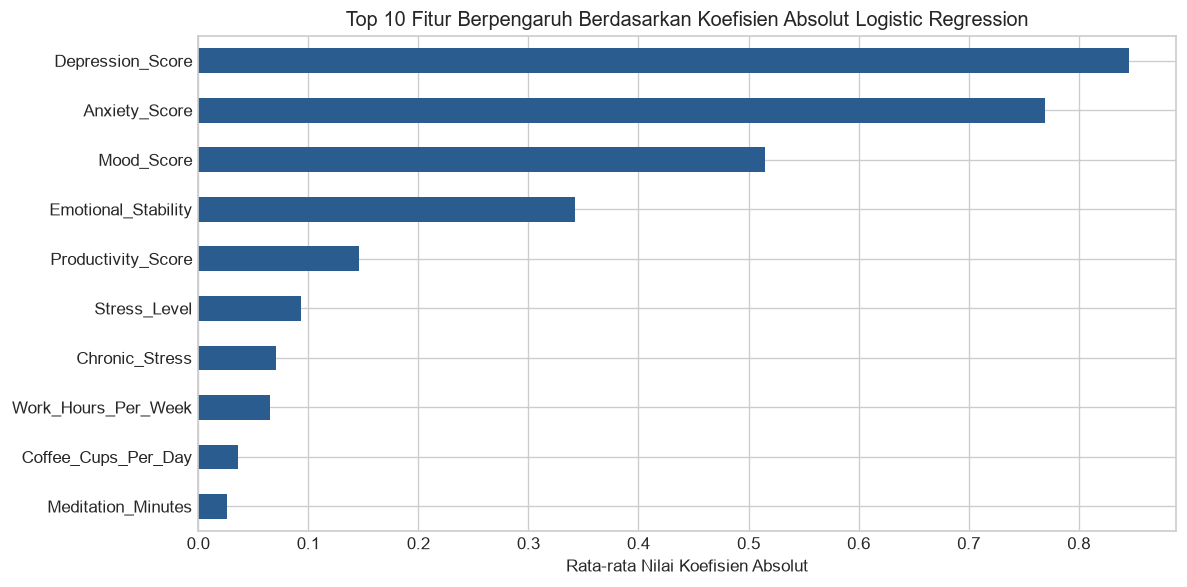

In [23]:
top_features = np.abs(classifier.coef_).mean(axis=0)
top_features_series = pd.Series(
    top_features,
    index=X.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_features_series.plot(
    kind='barh',
    color='#2b5c8f'
)
plt.title('Top 10 Fitur Berpengaruh Berdasarkan Koefisien Absolut Logistic Regression')
plt.xlabel('Rata-rata Nilai Koefisien Absolut')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/top_features_logistic_regression.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [24]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_logistic_regression_elastic_net.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [25]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_logistic_regression_elastic_net.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [26]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_logistic_regression_elastic_net.csv',
    index=False
)